#### 복습
- LLM = 대규모 언어 모델 (언 어!!)
- 에이전트 = 특정 작업을 수행하는 주체 (모델, 도구, 실행절차를 가진 주체...)
- Tool = 에이전트가 사용하는 도구 (예: 데이터베이스, API, 파일 시스템 등)
- State = 그래프에서 전체적으로 값을 기억하고 기록하는 역할
- Node = 그래프에서 상태를 나타내는 단위(내부적으론 함수로 나타냄)
- Edge = 그래프에서 노드 간의 관계를 나타내는 단위
- 노드와 에이전트의 차이점:
    - 노드: 그래프 안에서 실행단이 1개임
        - 노드는 llm이 들어있을수도 있고 단순한 함수일 수도 있음(안들어있을수도 있다는 말)
    - 에이전트: 목표를 가지고 실행할 수 있는 시스템이고 노드를 포함할 수 있음
        - 에이전트는 무조건 llm을 가지고 있어야 함
        - 즉, 에이전트는 여러 노드를 조합하여 복잡한 작업을 수행할 수 있음

![복습이미지](./images/ref/06_01.png)

___
```Markdown - 서론
이제는 시작이 있으면 llm에게 질문을 던지고 이 llm자체가 '검색이 필요한데?'하고 검색을 할건데
이 검색하는 툴 중에(Tavli...말고도 여러개 많음) 어떤 툴을 사용할지 llm이 판단해서 검색을 수행하게 될 것임

그럼 저 검색툴도 노드로 등록되어야 있어야 했는데
에이전트를 하나 만들어서 검색 엔진을 다 집어넣어두고
하나의 특정 전문 분야들끼리 묶어 에이전트를 만들고?

그 여러 에이전트들을 = 전문가 집단을 만들어 협업하게 할 수 있음!!
```

# **1. 멀티 에이전트**
- 단일 Agent가 조사, 분석, 작성, 검수까지 모두 맡으면 프롬프트가 복잡해지고, 실패 지점이나 책임을 구분하기 어려움!
- Multi Agent는 작업을 역할별로 나누고, 각 결과를 다음 담당자에게 전달함~!! (전문가 집단!)
    - [Multi Agent 종류]
    - Network: 동료 간 상호 위임이 가능한 연결 구조(거미줄처럼 연결되어있음)
    - Supervisor: 여러 담당자의 순서를 결정하는 중앙 관리자(나머지 에이전트를 컨트롤하는 심판 역할)
    - Hierarchical: 팀 안에 팀이 있는 계층적인 조직(Supervisor 확장판으로, 여러 계층의 관리자가 존재함)
    - Custom: 특정 요구사항에 맞게 설계된 맞춤형 구조(내가 만들고싶은 상태로 수정해서 만드는~~ | 위 3개가 기본적인거임)


### **1-1. 용어 설명**

#### 1-1-1. HandOff
- 현재 담당자가 다른 담당자에게 실행 제어권을 넘기는 것
- 그래프상에서 에이전트가 서로 다른 경우를 말하는데, 한 에이전트가 수행하던 작업을 다른 에이전트가 이어받아 수행하게 되는 상황을 의미함.

In [2]:
from typing import TypedDict
from langgraph.graph import StateGraph, START, END

In [3]:
# 에이전트 간 공유할 상태
class HandoffState(TypedDict, total=False):
    request: str        # 사용자 요청
    department: str     # 담당 부서
    answer: str         # 답변

# 요청 내용에 따라 담당 부서 결정
def triage(state: HandoffState):
    text = state["request"].lower()
    dept = "coding" if any(k in text for k in ("파이썬", "코드", "python", "for문")) else "writing"
    return {"department": dept}

# 코딩 담당: 코드 예제 반환
def coding(state: HandoffState):
    return {"answer": f"[코딩 담당] {state['request']} > 예제: for x in [1, 2, 3]: print(x)"}

# 글쓰기 담당: 글 구성 안내 반환
def writing(state: HandoffState):
    return {"answer": f"[글쓰기 담당] {state['request']} > 도입/본문/마무리로 구성하세요"}

# 결정된 담당 부서로 이동할 경로 반환
def route_handoff(state: HandoffState):
    return state["department"]

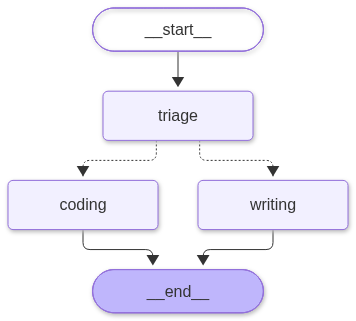

In [4]:
builder = StateGraph(HandoffState)

builder.add_node("triage", triage)
builder.add_node("coding", coding)
builder.add_node("writing", writing)

builder.add_edge(START, "triage")
builder.add_conditional_edges("triage", route_handoff, {"coding": "coding", "writing": "writing"})
builder.add_edge("coding", END)
builder.add_edge("writing", END)

handoff_graph = builder.compile()
handoff_graph

In [5]:
for q in ["파이썬 for문 설명해줘", "감사 인사말을 작성해줘"]:
    print(handoff_graph.invoke({"request": q}))

{'request': '파이썬 for문 설명해줘', 'department': 'coding', 'answer': '[코딩 담당] 파이썬 for문 설명해줘 > 예제: for x in [1, 2, 3]: print(x)'}
{'request': '감사 인사말을 작성해줘', 'department': 'writing', 'answer': '[글쓰기 담당] 감사 인사말을 작성해줘 > 도입/본문/마무리로 구성하세요'}


In [6]:
# stream_mode="updates": 과정이 보임
# 근데 지금은 단일 에이전트고 멀티에이전트로 바꾸려면 아래 코드셀 확인!
for update in handoff_graph.stream({"request": "파이썬 리스트 예제"}, stream_mode="updates"):
    print(update)

{'triage': {'department': 'coding'}}
{'coding': {'answer': '[코딩 담당] 파이썬 리스트 예제 > 예제: for x in [1, 2, 3]: print(x)'}}


In [7]:
from langchain_openai import ChatOpenAI
from langgraph.types import Command
from typing import TypedDict, Literal

In [8]:
llm = ChatOpenAI(model="gpt-5.6-luna", temperature=0)

# ★★ 1. 분류 에이전트(노드 아님!!)
# Command: 실질적으로 Handoff를 실행하는건데 (이게 이제 에이전트들과 주고받기가 가능하게 해주는거임)
# Literal: 특정 값만 허용하도록 타입 지정
def triage(state: HandoffState) -> Command[Literal["coding", "writing"]]:
    text = state["request"].lower()
    dept = "coding" if any(k in text for k in ("파이썬", "코드", "python", "for문")) else "writing"
    # goto: 이동할 에이전트 지정(명령어임) -> 다음에 실행할 노드 지정과 같은 말
    # update: 공유 상태(State)에 department 정보를 저장함
    return Command(update={"department": dept}, goto=dept)


# ★★ 2. 코딩 에이전트(노드 아님!!)
def coding(state: HandoffState):
    response = llm.invoke(
        f"당신은 파이썬 전문 강사입니다. 쉽게 설명하세요. \n질문: {state['request']}"
    )
    return {"answer": response.content}


# ★★ 3. 글쓰기 에이전트(노드 아님!!)
def writing(state: HandoffState):
    response = llm.invoke(
        f"당신은 전문 작가입니다. 자연스럽게 글을 작성하세요. \n요청: {state['request']}"
    )
    return {"answer": response.content}

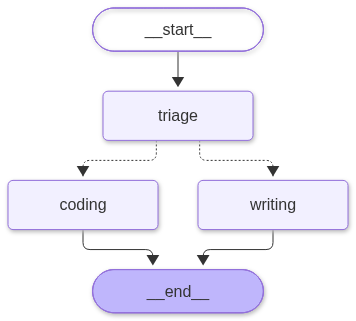

In [9]:
# 이제 위에걸로 그래프 구성!
builder = StateGraph(HandoffState)

builder.add_node("triage", triage)
builder.add_node("coding", coding)
builder.add_node("writing", writing)

# 멀티 에이전트에선 add_conditional_edges가 필요 없고, triage에서 바로 각 에이전트로 이동함(goto 사용)
builder.add_edge(START, "triage")
builder.add_edge("coding", END)
builder.add_edge("writing", END)

graph = builder.compile()
graph

In [10]:
for q in ["파이썬 for문 설명해줘", "감사 인사말을 작성해줘"]:
    result = graph.invoke({"request": q})
    print(f"\n질문: {q}")
    print(f"담당: {result['department']}")
    print(f"답변: {result['answer']}")


질문: 파이썬 for문 설명해줘
담당: coding
답변: 파이썬의 `for`문은 **여러 개의 데이터를 하나씩 꺼내 반복해서 실행할 때** 사용합니다.

## 1. 기본 형태

```python
for 변수 in 반복할_데이터:
    실행할_코드
```

예를 들어 리스트의 값을 하나씩 출력할 수 있습니다.

```python
fruits = ["사과", "바나나", "포도"]

for fruit in fruits:
    print(fruit)
```

실행 결과:

```text
사과
바나나
포도
```

동작 방식은 다음과 같습니다.

1. `fruits`에서 `"사과"`를 꺼내 `fruit`에 저장
2. `print(fruit)` 실행
3. `"바나나"`를 꺼내 다시 실행
4. `"포도"`까지 반복

---

## 2. `range()`와 함께 사용하기

`range()`는 숫자 범위를 만들어 줍니다.

```python
for i in range(5):
    print(i)
```

결과:

```text
0
1
2
3
4
```

`range(5)`는 **0부터 5보다 작은 수까지**를 의미합니다.

### 1부터 5까지 출력

```python
for i in range(1, 6):
    print(i)
```

결과:

```text
1
2
3
4
5
```

형식은 다음과 같습니다.

```python
range(시작값, 끝값)
```

단, `끝값`은 포함되지 않습니다.

### 2씩 증가하기

```python
for i in range(0, 10, 2):
    print(i)
```

결과:

```text
0
2
4
6
8
```

형식:

```python
range(시작값, 끝값, 증가값)
```

---

## 3. 문자열 반복하기

문자열도 한 글자씩 반복할 수 있습니다.

```python
word = "Python"

for letter in word:
    print(letter)
```

결과:

```text

![에이전트와 멀티에이전트 차이](./images/ref/06_02.png)

### **1-2. 종류1) Network**
각 전문 에이전트로 되어 있으며 직접 이웃 에이전트로 handoff를 한다.

In [11]:
from tavily import TavilyClient
from dotenv import load_dotenv
from pathlib import Path
from pydantic import BaseModel, Field  # llm이 값을 줄 때 구조화시켜 줄 수 있도록 하는..
import os, json
import matplotlib.pyplot as plt

In [12]:
load_dotenv()

True

In [13]:
if not os.getenv("OPENAI_API_KEY"):
    raise RuntimeError(".env 파일에 OPENAI API KEY가 설정되어 있지 않습니다.")

llm = ChatOpenAI(model=os.getenv("OPENAI_MODEL", "gpt-5.6-luna"), temperature=0)

In [14]:
OUTPUT_DIR = Path("multi_agent_outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

[에이전트를 네트워크형식으로 구현해볼게~]

In [15]:
# llm에게 지시와 사용자 입력을 구분해서 질문 보냄
def ask(system: str, user: str) -> str:
    """시스템 지시와 사용자 입력을 구분해 LLM을 호출합니다."""
    response = llm.invoke([("system", system), ("human", user)])
    return str(response.content)

In [16]:
# 차트 상태
class ChartState(TypedDict, total=False):
    question: str
    sources: list[dict]
    data: list[dict]
    summary: str
    chart_path: str
    error: str

# 차트 데이터
class ChartData(TypedDict):
    label: str
    value: float

In [17]:
# 웹 검색 함수
def search_web(query: str) -> list[dict]:
    key = os.getenv("TAVILY_API_KEY")
    if not key:
        raise RuntimeError(".env 파일에 TAVILY API KEY가 설정되어 있지 않습니다.")
    result = TavilyClient(api_key=key).search(query=query, max_results=5)
    return [{
        "title": x.get("title", ""), 
        "url": x.get("url", ""), 
        "content": x.get("content", "")[:1500]
    } for x in result.get("results", [])]

In [18]:
# llm이 주는 값을 구조화시킴
class ResearchData(BaseModel):
    data: list[ChartData] = Field(description="출처에서 확인된 수치만 포함!")
    summary: str

In [19]:
# 구조화된 출력이 가능한 llm 생성함
research_llm = llm.with_structured_output(ResearchData)

In [20]:
# 연구자 역할을 수행해서 검색결과 분석하고, 검증 가능한 수치 추출함
def resercher(state: ChartState) -> Command[Literal["chart", "__end__"]]:
    # 사용자 질문 기반으로 웹 검색 수행
    sources = search_web(state["question"])
    # 검색 결과에서 검증 가능한 수치를 추출
    parsed = research_llm.invoke([
        ("system", "검색 결과에 명시된 값만 추출하세요. 추정하거나 없는 수치를 생성하지 마세요. 각 수치의 단위가 일관되어야 합니다. 확인 불가능하면 data를 빈 목록으로 반환하세요."),
        ("human", json.dumps({"question": state["question"], "sources": sources}, ensure_ascii=False))
    ])

    # parsed 데이터가 없으면 에러 저장 후 종료
    if not parsed.data:
        return Command(update={
            "sources": sources,
            "error": "검증 가능한 수치가 없습니다."
        }, goto=END)
    # 그게 아니라면(데이터가 있다면)
    # 검색 결과, 수치, 요약을 저장하고 차트노드로 이동
    return Command(update={
        "sources": sources,
        "data": [x.model_dump() if hasattr(x, "model_dump") else x for x in parsed.data],
        "summary": parsed.summary
    }, goto="chart")

In [21]:
def chart(state: ChartState) -> Command[Literal["__end__"]]:
    rows = state["data"]
    fig, ax = plt.subplots(figsize=(9, 4))
    ax.bar([r["label"] for r in rows], [r["value"] for r in rows])
    ax.set_title("Research results (verify units and sources)")
    ax.tick_params(axis="x", rotation=25)
    fig.tight_layout()
    path = OUTPUT_DIR / "research_chart.png"
    fig.savefig(path, dpi=140)
    plt.show()
    plt.close(fig)
    return Command(update={"chart_path":str(path)}, goto=END)

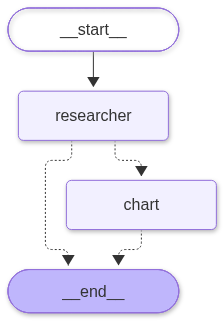

In [22]:
builder = StateGraph(ChartState)

builder.add_node("researcher", resercher)
builder.add_node("chart", chart)
# END를 쓸 필요가 없음
# why?! 
# 위에서 Command(goto=END)를 사용했으니까 여기서 END 정의 안해도됨 쩐다!!

builder.add_edge(START, "researcher")
network_chart = builder.compile()
network_chart

In [23]:
# 맷플로립 한글깨짐 방지
import matplotlib as mpl

# 한글 폰트 설정 (Windows)
mpl.rcParams["font.family"] = "Malgun Gothic"
# 마이너스(-) 기호 깨짐 방지
mpl.rcParams["axes.unicode_minus"] = False

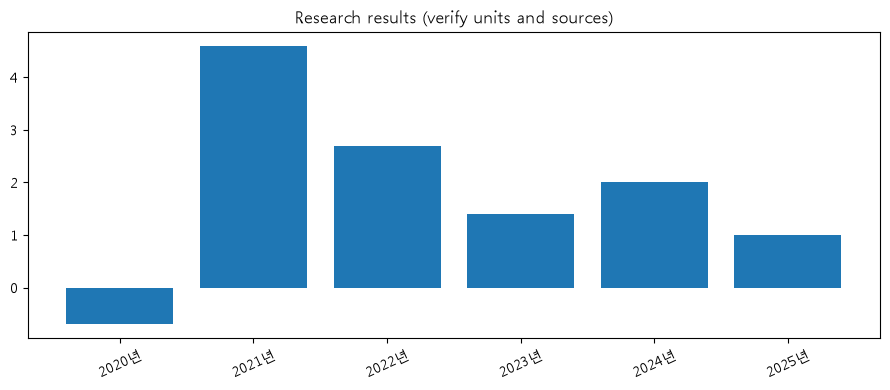

In [24]:
result = network_chart.invoke(
    {"question": "2020년부터 2025년까지 한국의 연도별 실질 GDP 성장률(%)"}, 
    config={"recursion_limit": 5}
)

#### 2-1-1. 실습) 멀티 에이전트 기반(Network) AI 맞춤형 학습 진단 및 문제 출제 시스템
학생의 과목별 학습 점수를 분석해 가장 취약한 학습 영역을 찾아내고, 해당 영역에 대한 맞춤형 문제를 자동으로 출제하는 AI 학습 진단 멀티 에이전트 시스템 개발해보기

- Diagnosis Agent: 학생의 영역별 점수를 분석하고 가장 취약한 영역을 찾아 학습 진단 결과를 작성
- Quiz Agent: 진단 결과를 받아 취약 영역에 대한 객관식 문제 생상

```
scores = {"파이썬 기초문법": 90, "데이터 분석": 75, "딥러닝": 60}

1. 학생의 학습 점수를 입력받음
2. 모든 점수가 0~100점 사이인지 검사
3. 가장 점수가 낮은 학습 영역을 찾음
4. llm을 이용해 학생의 학습 상태를 3문장으로 진단
5. 진단 결과를 문제 출제 에이전트에게 전달
6. llm을 이용해 취약 영역에 대한 객관식 문제 3개를 생성
7. 각 문제에 정답과 해설을 포함
8. 최종 진단 결과와 생성된 문제를 출력
```

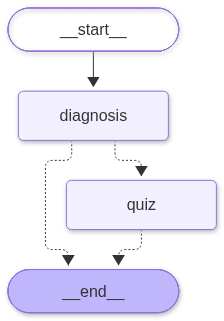

In [25]:
# 에이전트들이 공유할거
class StudyStatemy(TypedDict, total=False):
    scores: dict[str, int]
    down_subject: str
    diagnosis: str
    quiz_ss: list[dict]
    error: str


# 첫번째 에이전트: Diagnosis Agent
def diagnosismy(state: StudyStatemy) -> Command[Literal["quiz", "__end__"]]:
    # 1단계) 과목별 점수 가져옴
    scores = state["scores"]
    # 2단계) 점수 검사(0~100점)
    if not scores or any(
        type(score) not in (int, float) or not 0 <= score <= 100
        for score in scores.values()
    ):
        return Command(
            update={"error": "점수는 0~100 사이여야 합니다."}, goto=END
        )
    # 3단계) 가장 점수 낮은애
    down_subject = min(scores, key=scores.get)
    # 4단계) llm 이용해서 3문장 진단하기
    response = llm.invoke([
        ("system", "학습 진단 전문가가 되어 학생의 과목별 점수를 분석하고 학습 상태를 3문장으로 진단하세요."),
        ("human", f"과목별 점수: {scores} | 취약 과목: {down_subject}")
    ])
    # 5단계) 결과 문제 출제 에이전트에 전달하기
    return Command(
        update={
            "down_subject": down_subject,
            "diagnosis": str(response.content)
        }, goto="quiz"
    )

# 객관식 문제 하나의 구조 정의 -> 이것도 해야지!!
class QuizDatamy(TypedDict):
    question: str
    options: list[str]
    answer: int
    explanation: str

# llm이 주는 값 구조화 시키기
class ResearchQuizmy(BaseModel):
    # quiz_ss: list[dict[str, str]] 이걸 이렇게 쓰면 안돼고..아래처럼 써야지!!
    quiz_ss: list[QuizDatamy] = Field(
        description="취약 과목에 대한 객관식 4지선다 문제 3개와 각 문제의 정답 번호, 해설"
    )

# llm 생성
quiz_llm = llm.with_structured_output(ResearchQuizmy)

# 두번째 에이전트 Quiz Agent
def quiz(state: StudyStatemy) -> Command[Literal["__end__"]]:
    # 첫번째 에이전트가 전달한 결과 받아옴
    down_subject = state["down_subject"]
    diagnosis = state["diagnosis"]
    # 6단계 + 7단계) llm 이용해서 문제 만듦
    parsed = quiz_llm.invoke([
        ("system", "학습 문제 출제 전문가가 되어 학생의 취약 과목과 학습 진단 결과를 합고해 객관식 4지선다 문제를 3개 생성하세요. 문제는 정답과 해설을 포함하세요."),
        ("human", f"취약 과목: {down_subject} | 진단: {diagnosis}")
    ])
    # 문제 출제 끝. 그래프 종료
    return Command(
        update={"quiz_ss": parsed.quiz_ss}, goto=END
    )


# 이제 그래프 그려
mybuilder = StateGraph(StudyStatemy)

mybuilder.add_node("diagnosis", diagnosismy)
mybuilder.add_node("quiz", quiz)

mybuilder.add_edge(START, "diagnosis")

my_graph = mybuilder.compile()
my_graph

In [26]:
# 이제 실행해보자
scores = {
    "파이썬 기초문법": 90,
    "데이터 분석": 75,
    "딥러닝": 60
}

result = my_graph.invoke({"scores": scores})
result

{'scores': {'파이썬 기초문법': 90, '데이터 분석': 75, '딥러닝': 60},
 'down_subject': '딥러닝',
 'diagnosis': '파이썬 기초문법은 90점으로 기초 코딩 역량이 매우 탄탄합니다.  \n데이터 분석은 75점으로 기본 개념은 갖추었지만, 실습과 문제 해결 경험을 늘리면 향상될 수 있습니다.  \n딥러닝은 60점으로 가장 취약하므로, 선형대수·확률 기초를 보완하고 신경망 구조와 학습 과정을 작은 프로젝트로 반복 학습하는 것이 필요합니다.',
 'quiz_ss': [{'question': '신경망에서 입력값 x와 가중치 w의 내적에 편향 b를 더한 뒤 활성화 함수에 전달하는 식으로 가장 알맞은 것은 무엇인가요?',
   'options': ['z = x + w + b',
    'z = xw + b',
    'z = x · w + b',
    'z = x · w × b'],
   'answer': 3,
   'explanation': '신경망의 한 뉴런은 입력 벡터와 가중치 벡터의 내적 x · w를 계산한 후 편향 b를 더해 z = x · w + b를 구합니다. 이후 z에 활성화 함수를 적용합니다.'},
  {'question': '이진 분류 신경망의 출력층에서 시그모이드 함수의 출력값이 0.8로 나왔다면, 일반적으로 어떻게 해석할 수 있나요?',
   'options': ['입력 데이터가 두 클래스 중 1번 클래스에 속할 확률이 약 80%이다.',
    '모델의 가중치가 모두 0.8이다.',
    '손실 함수의 값이 0.8이라는 뜻이다.',
    '입력 데이터의 특성 개수가 0.8개라는 뜻이다.'],
   'answer': 1,
   'explanation': '시그모이드 함수는 값을 0과 1 사이로 변환하므로 이진 분류에서 특정 클래스에 속할 확률로 해석할 수 있습니다. 출력값이 0.8이면 해당 클래스의 예측 확률이 약 80%라는 의미입니다.'},
  {'question': '경사하강법에서 학습률(lea

In [27]:
# 검증도 - GPT도움
if result.get("error"):
    print("오류:", result["error"])

else:
    print("===== 학습 진단 =====")
    print("취약 과목:", result["down_subject"])
    print("진단:", result["diagnosis"])

    print("\n===== 객관식 문제 =====")

    for i, q in enumerate(result["quiz_ss"], start=1):
        print(f"\n문제 {i}. {q['question']}")

        for j, option in enumerate(q["options"], start=1):
            print(f"{j}. {option}")

        print(f"정답: {q['answer']}번")
        print(f"해설: {q['explanation']}")

===== 학습 진단 =====
취약 과목: 딥러닝
진단: 파이썬 기초문법은 90점으로 기초 코딩 역량이 매우 탄탄합니다.  
데이터 분석은 75점으로 기본 개념은 갖추었지만, 실습과 문제 해결 경험을 늘리면 향상될 수 있습니다.  
딥러닝은 60점으로 가장 취약하므로, 선형대수·확률 기초를 보완하고 신경망 구조와 학습 과정을 작은 프로젝트로 반복 학습하는 것이 필요합니다.

===== 객관식 문제 =====

문제 1. 신경망에서 입력값 x와 가중치 w의 내적에 편향 b를 더한 뒤 활성화 함수에 전달하는 식으로 가장 알맞은 것은 무엇인가요?
1. z = x + w + b
2. z = xw + b
3. z = x · w + b
4. z = x · w × b
정답: 3번
해설: 신경망의 한 뉴런은 입력 벡터와 가중치 벡터의 내적 x · w를 계산한 후 편향 b를 더해 z = x · w + b를 구합니다. 이후 z에 활성화 함수를 적용합니다.

문제 2. 이진 분류 신경망의 출력층에서 시그모이드 함수의 출력값이 0.8로 나왔다면, 일반적으로 어떻게 해석할 수 있나요?
1. 입력 데이터가 두 클래스 중 1번 클래스에 속할 확률이 약 80%이다.
2. 모델의 가중치가 모두 0.8이다.
3. 손실 함수의 값이 0.8이라는 뜻이다.
4. 입력 데이터의 특성 개수가 0.8개라는 뜻이다.
정답: 1번
해설: 시그모이드 함수는 값을 0과 1 사이로 변환하므로 이진 분류에서 특정 클래스에 속할 확률로 해석할 수 있습니다. 출력값이 0.8이면 해당 클래스의 예측 확률이 약 80%라는 의미입니다.

문제 3. 경사하강법에서 학습률(learning rate)을 지나치게 크게 설정했을 때 나타날 가능성이 가장 높은 현상은 무엇인가요?
1. 가중치가 전혀 업데이트되지 않는다.
2. 손실이 진동하거나 발산하여 최적점에 도달하지 못할 수 있다.
3. 항상 한 번의 반복만으로 최적의 가중치를 찾는다.
4. 훈련 데이터의 특성 개수가 자동으로 줄어든다.
정답: 2번
해설: 학습률은 가중치를 얼

이 아래가 강사님 코드!!

In [28]:
class StudyState(TypedDict, total=False):
    scores: dict[str, int]
    weakness: str
    diagnosis: str
    quiz: str

def diagnosis(state: StudyState) -> Command[Literal["quiz"]]:
    scores = state["scores"]
    if not scores or any(not 0 <= v <= 100 for v in scores.values()):
        raise ValueError("영역별 점수를 0~100 사이로 입력하세요")
    weak = min(scores, key=scores.get)
    explanation = ask(
        "당신은 친절한 학습 진단 전문가입니다. 점수의 의미를 과장하지 말고 3문장으로 분석하세요", 
        f"영역별 점수: {scores}, 취약 과목: {weak}"
    )
    return Command(update={"weakness": weak, "diagnosis": explanation}, goto="quiz")

def quiz(state: StudyState) -> Command[Literal["__end__"]]:
    content = ask(
        "당신은 학습문제 출제 전문가입니다. 지정된 취약 과목에 대해 객관식 3문제를 만들고 각 문항에 정답과 쉬운 해설을 붙이세요. 애매한 문항은 피하세요.",
        f"취약 과목: {state['weakness']} | 진단: {state['diagnosis']}"
    )
    return Command(update={"quiz": content}, goto=END)

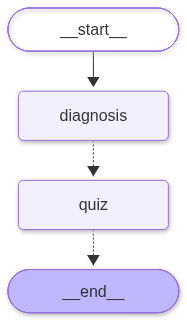

In [29]:
builder = StateGraph(StudyState)
builder.add_node("diagnosis", diagnosis)
builder.add_node("quiz", quiz)
builder.add_edge(START, "diagnosis")
study_network = builder.compile()
study_network

In [30]:
result = study_network.invoke(
    {"scores": {"파이썬 기초문법": 90, "데이터 분석": 75, "딥러닝": 60}},
    config={"recursion_limit": 5}
)

In [31]:
print("[진단]", result["diagnosis"], "\n[문제]", result["quiz"])

[진단] 파이썬 기초문법은 90점으로 기본 문법 이해도가 높은 편입니다.  
데이터 분석은 75점으로 대체로 이해하고 있으나 실습과 응용 문제에서 보완이 필요하며, 딥러닝은 60점으로 다른 영역보다 취약합니다.  
딥러닝의 핵심 개념과 모델 학습 과정을 기초부터 복습하고, 간단한 실습을 반복하며 이해도를 점검하는 것이 좋습니다. 
[문제] ## 딥러닝 기초 객관식 문제

### 1. 신경망에서 활성화 함수의 주요 역할은 무엇인가요?

① 데이터를 항상 정렬한다.  
② 신경망에 비선형성을 추가한다.  
③ 학습 데이터를 자동으로 삭제한다.  
④ 가중치를 모두 0으로 만든다.  

**정답: ②**

**쉬운 해설:**  
활성화 함수는 신경망에 **비선형성**을 추가합니다. 덕분에 신경망은 단순한 직선 관계가 아닌 복잡한 패턴도 학습할 수 있습니다. 대표적인 활성화 함수로 ReLU, Sigmoid, Tanh가 있습니다.

---

### 2. 딥러닝 모델을 학습할 때 손실 함수의 역할은 무엇인가요?

① 모델의 예측값과 실제 정답의 차이를 계산한다.  
② 학습 데이터를 무작위로 생성한다.  
③ 신경망의 층 개수를 자동으로 결정한다.  
④ 입력 데이터를 항상 이미지로 변환한다.  

**정답: ①**

**쉬운 해설:**  
손실 함수는 모델의 예측값이 실제 정답과 얼마나 다른지 나타내는 값입니다. 일반적으로 손실이 작을수록 모델의 예측이 정답에 가깝다는 뜻입니다. 모델은 손실을 줄이는 방향으로 학습합니다.

---

### 3. 경사하강법(Gradient Descent)의 기본적인 목적은 무엇인가요?

① 손실 함수를 최소화하는 방향으로 가중치를 업데이트한다.  
② 학습이 끝난 모델의 입력 데이터를 삭제한다.  
③ 모든 가중치를 같은 값으로 고정한다.  
④ 신경망의 출력값을 항상 0으로 만든다.  

**정답: ①**

**쉬운 해설:**  
경사하강법은 손실이 줄어드는 방향을 계산하여 모델의 가중치를 조금씩 수정하는 방법입니다. 반복해서 가중치를

### **1-3. 종류2) Supervisor**
Supervisor가 여러 전문 에이전트에게 작업을 순서대로 맡기고, 모든 작업이 끝나면 결과를 반환하는 구조

In [32]:
# total=False : 이 안에 있는 모든 데이터가 다 채워질 필요 없다는 뜻
class TripState(TypedDict, total=False):
    request: str             # 사용자의 여행 요청
    sources: list[dict]      # 웹 검색 결과
    research: str            # 조사 에이전트가 작성한 요약
    recommendation: str      # 추천 에이전트가 작성한 결과
    saved_path: str          # 저장된 파일 경로
    next_step: str           # LLM이 선택한 다음 작업
    error: str               # 오류 정보를 기록하기 위한 필드

class RouterDecision(BaseModel):
    next_step: Literal["search_agent", "recommendation_agent", "save_agent", "FINISH"]

In [33]:
router_llm = llm.with_structured_output(RouterDecision)

#### 아래 코드 설명 가지뻗기
- next함수란? 조건함수로 True가 되는 첫 번째 값을 반환하는 함수
- iter함수란? 반복 가능한 객체를 반환하는 함수, 여기선 dict_items를 반복 가능하게 만들어줌
- 그럼 이터러블과 이터레이터의 차이는?
- 이터러블은 반복 가능한 객체이고, 이터레이터는 실제로 반복을 수행하는 객체

```
이터로 감싸면 이러터블이 이터레이터로 변환!
그럼 이게 데이터 순서를 가지니까 반복할 때 순서대로 값을 가져올 수 있는거임
```

In [34]:
# 여행 상태 확인하고 다음에 수행할 에이전트 결정
def supervisor(state: TripState) -> Command[Literal["search_agent", "recommend_agent", "save_agent", "__end__"]]:
    completed = {
        "search_agent": bool(state.get("research")),
        "recommend_agent": bool(state.get("recommendation")),
        "save_agent": bool(state.get("saved_path"))
    }

    # all: 모두 다 참일때만 다음 단계로 진행(지금 코드에선 END로 보내게 됨)
    if all(completed.values()):
        return Command(goto=END)

    # 여행 감독자에게 다음 수행할 작업을 결정하도록 요청
    decision = router_llm.invoke([
        ("system", "당신은 여행 작업 감독자입니다. 반드시 검색, 추천, 저장 순서로 진행하세요. 이미 완료한 작업은 반복하지 마세요. 다음 작업 이름만 선택하세요."),
        ("human", json.dumps({"request": state["request"], "completed": completed}, ensure_ascii=False))
    ])

    # 다음 수행할 작업을 결정한 후, 아직 완료되지 않은 첫 번째 작업을 expected로 설정
    expected = next(k for k, v in completed.items() if not v)

    return Command(update={"next_step": decision.next_step}, goto=expected)

In [35]:
# 여행 조사원 에이전트
def trip_search(state: TripState) -> Command[Literal["supervisor"]]:
    sources = search_web(state["request"] + "여행 추천 관광지 날씨 예보")
    text = ask(
        "여행 조사원입니다. 출처에 근거한 내용만 요약하고 날짜가 확인되지 않은 날씨는 확정하지 마세요.", 
        json.dumps(sources, ensure_ascii=False)
    )
    return Command(update={"sources": sources, "research": text}, goto="supervisor")

# 추천 전문가 에이전트
def trip_recommend(state: TripState) -> Command[Literal["supervisor"]]:
    text = ask(
        "여행 추천 전문가입니다. 조사 내용을 바탕으로 여행지 3곳과 이유, 날씨 확인 주의사항을 작성하세요. 검증되지 않은 운영시간, 예보는 쓰지 마세요.", 
        state["request"]+"\n"+state["research"]
    )
    return Command(update={"recommendation": text}, goto="supervisor")

# 여행 저장 담당자 에이전트
def trip_save(state: TripState) -> Command[Literal["supervisor"]]:
    path = OUTPUT_DIR / "trip_recommendation.md"
    refs = "\n".join("-"+s["url"] for s in state.get("sources", []))
    path.write_text(
        "# 여행 추천\n\n" + state["recommendation"] + 
        "\n\n### 참고 검색 링크(출처)\n\n" + refs, 
        encoding="utf-8"
    )
    return Command(update={"saved_path": str(path)}, goto="supervisor")

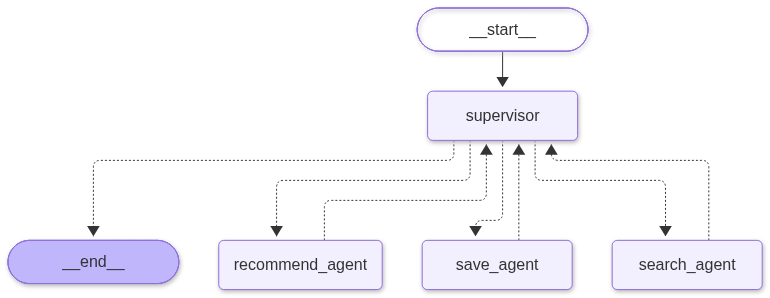

In [36]:
# 이제 그래프 만들기
builder = StateGraph(TripState)

# for문으로 돌면서 node 생성하기
for name, fn in [
    ("supervisor", supervisor),
    ("search_agent", trip_search),
    ("recommend_agent", trip_recommend),
    ("save_agent", trip_save)
]:
    builder.add_node(name, fn)

# edge는 하나만 걸면 됨
builder.add_edge(START, "supervisor")

trip_graph = builder.compile()
trip_graph

In [37]:
result = trip_graph.invoke({"request": "제주도 2박 3일 자연 경관 중심 여행지를 추천해줘"}, config={"recursion_limit": 10})

In [38]:
# result
print(result["recommendation"])
print("저장파일:", result["saved_path"])

제주도 **2박 3일 자연경관 중심 여행**이라면 이동 시간을 줄이기 위해 동부·남부를 중심으로 아래 3곳을 추천합니다.

## 1. 성산일출봉

- 제주 동부를 대표하는 화산 지형으로, 정상에서 성산 주변 해안과 우도를 조망하기 좋습니다.
- 이른 아침에는 일출 명소로 활용할 수 있고, 정상까지 오르지 않더라도 주변 해안 산책으로 경관을 즐길 수 있습니다.
- 다만 계단과 오르막이 있어 바람이 강하거나 비가 온 뒤에는 미끄럼에 주의해야 합니다.

**추천 시기:** 오전 또는 해 질 무렵  
**함께 둘러보기 좋은 곳:** 섭지코지, 성산 주변 해안

## 2. 비자림

- 오래된 비자나무 숲길을 걸으며 해안 관광지와 다른 제주 특유의 고요한 자연을 느낄 수 있습니다.
- 경사가 비교적 심한 산행보다는 숲길 산책에 가까워, 일정 중 휴식이 필요한 날 넣기 좋습니다.
- 비가 내린 뒤에는 숲의 분위기가 좋지만 바닥이 젖을 수 있으므로 미끄럼 방지 신발을 권합니다.

**추천 시기:** 오전 또는 한낮  
**함께 둘러보기 좋은 곳:** 월정리해변, 함덕해수욕장

## 3. 정방폭포

- 바닷가로 직접 떨어지는 폭포 경관을 볼 수 있는 제주 남부의 대표 자연 명소입니다.
- 폭포와 해안 풍경을 한 번에 감상할 수 있어 짧은 시간에도 여행 만족도가 높은 편입니다.
- 폭포 주변 계단과 바위 구간은 물기가 있을 수 있어 편한 신발이 적합합니다.

**추천 시기:** 비가 많이 온 직후에는 수량이 늘 수 있지만, 강풍·호우 때는 접근 안전을 우선해야 합니다.  
**함께 둘러보기 좋은 곳:** 서귀포 해안 산책로, 쇠소깍

## 2박 3일 동선 예시

### 1일 차: 동부 해안
- 성산일출봉
- 섭지코지
- 성산 또는 표선 일대 숙박

### 2일 차: 숲과 북동부 해안
- 비자림
- 월정리해변 또는 함덕해수욕장
- 제주 동부·동북부 숙박

### 3일 차: 서귀포 남부
- 정방폭포
- 쇠소깍 또는 서귀포 해안
- 제주공항 이동

공항 출·도착 시간에 따라 3일 차

### **1-4. 종류3) Hierarchical**
- 팀 내부에 여러 작업 노드를 두고, 각 팀을 독립적인 SubGraph로 구성하는 구조
- 계층형 멀티 에이전트
```
각각의 서브그래프를 만들어서..~
필요할 때 연결해서 쓰는!

위에 슈퍼바이저 에이전트를 여러개 둔거라 생각하면 쉬움
```

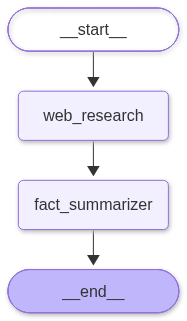

In [39]:
# [싱글 에이전트 1]
class ResearchTeamState(TypedDict, total=False):
    topic: str              # 조사항 주제
    sources: list[dict]     # 조사(웹) 검색 결과
    notes: str              # 검색 결과를 요약한 조사 노트


def find_sources(s: ResearchTeamState):
    return {"sources": search_web(s["topic"])}

def summarize_sources(s: ResearchTeamState):
    return {"notes": ask("당신은 조사전문가입니다. 제공된 검색 결과만 바탕으로 핵심 사실을 요약하고 불확실한 부분은 표시하세요.", json.dumps(s["sources"], ensure_ascii=False))}


research_builder = StateGraph(ResearchTeamState)

research_builder.add_node("web_research", find_sources)
research_builder.add_node("fact_summarizer", summarize_sources)

research_builder.add_edge(START, "web_research")
research_builder.add_edge("web_research", "fact_summarizer")
research_builder.add_edge("fact_summarizer", END)

research_team = research_builder.compile()
research_team

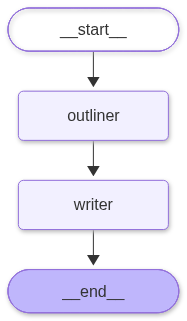

In [40]:
# [싱글 에이전트 2]
class WritingTeamState(TypedDict, total=False):
    topic: str      # 보고서 주제
    notes: str      # 조사팀에서 작성한 조사 노트
    outline: str    # 보고서 목차 및 개요
    report: str     # 최종 보고서 


def outline_writer(s: WritingTeamState):
    return {"outline": ask("당신은 문서 기획자입니다. 조사 노트만을 활용하여 제목과 3~4개 소제목으로 개요를 만드세요.", s["topic"]+"\n"+s["notes"])}

def report_writer(s: WritingTeamState):
    return {"report": ask("당신은 보고서 작성 전문가입니다. 개요와 조사 노트만을 사용하여 한국어 마크다운 보고서를 작성하세요. 불확실한 정보는 불확실하다고 표시하세요.", json.dumps(s, ensure_ascii=False))}


writing_builder = StateGraph(WritingTeamState)

writing_builder.add_node("outliner", outline_writer)
writing_builder.add_node("writer", report_writer)

writing_builder.add_edge(START, "outliner")
writing_builder.add_edge("outliner", "writer")
writing_builder.add_edge("writer", END)

writing_team = writing_builder.compile()
writing_team

In [41]:
# [이제 두 에이전트를 엮어서 사용]
class TopState(TypedDict, total=False):
    topic: str
    notes: str
    sources: list[dict]
    outline: str
    report: str
    saved_path: str

class TeamChoice(BaseModel):
    team: Literal["research_team", "writing_team", "FINISH"]

top_router = llm.with_structured_output(TeamChoice)

# 상위 감독자 및 팀 실행 함수 정의
def top_supervisor(s: TopState) -> Command[Literal["research_team", "writing_team", "__end__"]]:
    if s.get("report"):
        return Command(goto=END)
    choice = top_router.invoke([
        ("system", "상위 감독자입니다. 조사 노트가 없으면 research_team, 조사 노트가 있고 보고서가 없으면 writing_team을 선택하세요."),
        ("human", json.dumps({"topic": s["topic"], "has_notes": bool(s.get("notes")), "has_report": bool(s.get("report"))}, ensure_ascii=False))
    ])
    expected = "writing_team" if s.get("notes") else "research_team"
    return Command(goto=expected)

# 조사팀 실행 함수 정의
def run_research(s: TopState) -> Command[Literal["top_supervisor"]]:
    out = research_team.invoke({"topic": s["topic"]}, config={"recursion_limit": 10})
    return Command(update={"notes": out["notes"], "sources": out["sources"]}, goto="top_supervisor")

# 작성팀 실행 함수 정의
def run_writing(s: TopState) -> Command[Literal["top_supervisor"]]:
    out = writing_team.invoke({"topic": s["topic"], "notes": s["notes"]}, config={"recursion_limit": 10})
    path = OUTPUT_DIR / "agent_report.md"
    refs = "\n".join("- " + x["url"] for x in s["sources"])
    path.write_text(out["report"] + "\n\n### 검색 출처\n" + refs, encoding="utf-8")
    return Command(update={"outline": out["outline"], "report": out["report"], "saved_path": str(path)}, goto="top_supervisor")

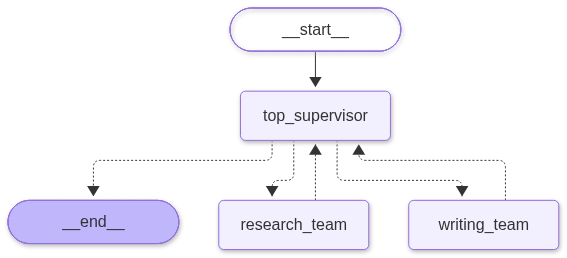

In [42]:
top_builder = StateGraph(TopState)

top_builder.add_node("top_supervisor", top_supervisor)
top_builder.add_node("research_team", run_research)
top_builder.add_node("writing_team", run_writing)

top_builder.add_edge(START, "top_supervisor")

hierarchical_graph = top_builder.compile()
hierarchical_graph

In [43]:
result = hierarchical_graph.invoke({"topic": "멀티 에이전트 시스템의 개념과 실제 활용 사례"}, config={"recursion_limit": 10})

print(result["report"])
print("보고서 저장 경로:", result["saved_path"])

# 멀티 에이전트 시스템의 개념과 실제 활용 사례

## 1. 멀티 에이전트 시스템의 개념과 작동 방식

### 1.1 멀티 에이전트 시스템이란

멀티 에이전트 시스템(Multi-Agent System, MAS)은 여러 자율 AI 에이전트가 정보를 공유하고 업무를 분담·조정하면서 공동의 목표를 달성하는 시스템이다. 단일 AI 에이전트가 모든 작업을 수행하는 대신, 각 에이전트가 데이터 분석, 자연어 처리, 의사결정, 프로세스 실행 등 특정 역할을 맡아 협업한다.

이러한 구조는 단순한 질의응답보다 복잡하고 다단계적인 업무를 처리하는 데 초점을 둔다. 예를 들어 하나의 업무를 문서 검색, 분석, 판단, 실행, 결과 검토 등의 단계로 나누고, 각 단계에 적합한 에이전트를 배정할 수 있다.

### 1.2 단일 에이전트와의 차이

단일 에이전트 시스템에서는 하나의 AI가 정보 수집부터 판단과 실행까지 대부분의 작업을 담당한다. 반면 멀티 에이전트 시스템은 다음과 같은 방식으로 작업을 분산한다.

- 여러 에이전트가 업무를 역할별로 분담
- 각 에이전트가 전문 영역에 집중
- 작업 결과를 다른 에이전트와 공유
- 중간 결과와 최종 목표를 조정
- 필요한 경우 새로운 에이전트를 추가해 기능을 확장

따라서 MAS는 대규모 업무나 여러 단계의 판단이 필요한 업무에 적합한 구조로 설명된다. 다만 여러 에이전트의 협업이 항상 단일 에이전트보다 우수하다고 단정할 수는 없다. 실제 성능과 비용은 업무의 복잡도, 시스템 설계, 데이터 품질 등에 따라 달라질 수 있다.

### 1.3 에이전트 간 협업 방식

MAS의 주요 작동 방식은 다음과 같다.

- **실시간 정보 공유:** 에이전트가 작업 과정에서 획득한 정보와 결과를 상호 교환
- **업무 분담:** 전체 목표를 세부 작업으로 나누어 각 에이전트에 할당
- **순차적 위임:** 한 에이전트의 결과를 다음 에이전트가 이어받아 작업 수행
- **결과 조정:** 서로 다른 분석이나 판단을 비교하고 공동 결과를 도출
- **의견

___
# **2. 종합 문제**

### **2-1. AI 소프트웨어 개발팀 구축**
- Hierachical 멀티 에이전트 구조로 직접 설계하고 구현
- AI 기반 소프트웨어 개발 자동화 서비스를 만드는 개발자
```
    학생 성적 관리 프로그램을 만들어줘. 학생 이름과 점수를 등록할 수 있고, 전체 학생 목록 조회, 평균 점수 계산, 최고 점수 학생 조회 기능이 필요해
```
- 기존의 단일 LLM 시스템은 이 요청을 받아 한 번에 코드를 생성(X) 
    - 기획팀: 사용자 요구사항을 분석하고 프로그램의 구조를 설계
    - 개발팀: 설계서를 바탕으로 Python 코드를 작성하고 품질을 검토
    - 상위 감독자: 기획팀과 개발팀의 작업 순서를 관리하고 최종 결과물을 완성

### **2-2. 요구 사항**
1. Top Supervisor
- 전체 프로젝트 진행을 관리하는 상위 감독자를 구현
- 현재 State를 확인하고 아래 규칙에 따라 작업을 배정
    - 설계서가 없다면 planning_team 실행
    - 설계서가 있고, 코드가 없다면 development_team 실행
    - 코드가 있고, 검토를 통과했다면 END
    - 코드 검토에 실패했다면 개발팀에 수정 요청

2. planning Team
- 기획팀 작업 순서 결정 노드
- 사용자 요구사항 분석 노드
- 함수, 자료구조, 프로그램 구조 설계 노드
- 기획팀의 최종 출력에는 아래 내용이 포함되어야 함
    - 프로젝트 목적
    - 필수 기능 목록
    - 사용할 자료구조
    - 함수 목록 및 함수별 역할
    - 예외 처리 요구사항

3. Development Team
- 개발 작업 순서 및 재작업 관리 노드
- 설계서 기반 Python 코드 작성
- 코드 품질 및 요구사항 충족 여부 검토
    - 필수 기능이 모두 구현되었는지
    - 문법적으로 올바른 Python 코드인지
    - 함수가 적절하게 분리되었는지
    - 예외 상황이 처리되었는지
    - 코드의 가독성이 적절한지

In [44]:
load_dotenv()

True

In [45]:
MODEL_NAME = os.getenv("OPENAI_API_KEY", "gpt-5.6-luna")
MAX_REVISIONS = 2   # 몇 번까지 수정할지? (최초 코드 생성 포함 X)

In [46]:
# Top Supervisor가 관리하는 전체 프로젝트의 상태
class ProjectState(TypedDict, total=False):
    request: str        # 사용자의 요청
    requirements: str   # 요구사항 분석 결과
    design: str         # 프로그램 설계서
    code: str           # 생성된 python 코드
    review: str         # 코드 검토 의견
    approved: bool      # 코드 승인 여부
    reviewed: bool      # 코드 검토 수행 여부
    revision_count: int # 코드 수정 횟수
    status: str         # 프로젝트 진행 상태(현재상태)
    saved_path: str     # 결과물 파일 저장 경로

# 이제 위에있는걸 쪼개~!

# 기획쪽
class PlanningState(TypedDict, total=False):
    request: str        
    requirements: str   
    design: str         

# 개발쪽
class DevelopmentState(TypedDict, total=False):
    request: str        
    requirements: str   
    design: str        
    code: str           
    review: str         
    approved: bool      
    reviewed: bool     
    revision_count: int 

답변에 대한 형식 이제 만들게

In [47]:
class ReviewResult(BaseModel):
    features_ok: bool = Field(description="필수 기능 구현 여부")
    syntax_ok: bool = Field(description="Python 문법 검토 여부")
    functions_ok: bool = Field(description="함수 분리 적절성")
    exceptions_ok: bool = Field(description="예외 처리 적절성")
    readability_ok: bool = Field(description="가독성 적절정")
    feedback: str = Field(description="문제점 및 구체적 수정 지침. 문제가 없으면 승인 근거")

    # 이 데코레이터가 하는 역할: approved 속성을 읽을 때 메서드가 아닌 속성처럼 접근 가능하게 함
    @property
    def approved(self) -> bool:
        # 안에것들이 모두 True가 되어야 통과!
        return all((self.features_ok, self.syntax_ok, self.functions_ok, self.exceptions_ok, self.readability_ok))

In [48]:
_llm = None         # 일반적인 LLM 호출
_review_llm = None  # 구조화된 코드 검토 결과 생성

# LLM 가져오기
def get_llm():
    global _llm
    if _llm is None:
        if not os.getenv("OPENAI_API_KEY"):
            raise RuntimeError("API KEY ERROR!")
        _llm = ChatOpenAI(model=MODEL_NAME, temperature=0)
    return _llm

# 구조화된 코드 검토용 LLM 가져오기
def get_review_llm():
    global _review_llm
    if _review_llm is None:
        _review_llm = get_llm().with_structured_output(ReviewResult)
    return _review_llm

# 일반적인 LLM 호출 함수
def ask(system: str, user: str) -> str:
    content = get_llm().invoke(["system", system, "human", user]).content
    if not isinstance(content, str):
        raise TypeError("LLM 응답이 문자열이 아닙니다. 응답 형식을 확인하세요.")
    return content.strip()

In [57]:
# Planning Team 요구사항 분석 > 설계
def planning_supervisor(s: PlanningState) -> Command[Literal["requirement_agent", "design_agent", "__end__"]]:
    if not s.get("requirements"):
        return Command(goto="requirement_agent")
    if not s.get("design"):
        return Command(goto="design_agent")
    return Command(goto="END")

# 요구사항 분석 에이전트
def requirement_agent(s: PlanningState) -> dict:
    result = ask(
        "당신은 요구사항 분석가입니다. 한국어 Markdown으로 반드시 다음 제목을 포함하세요: "
        "프로젝트 목적, 필수 기능 목록, 입력과 출력, 예외 처리 요구사항"
        "사용자 요청에 없는 요구사항을 임의로 필수화하지 마세요.",
        s["request"]
    )
    if not result:
        raise ValueError("요구사항 분석 결과가 비어 있습니다.")
    return {"requirements": result} 

# 디자인 에이전트
def design_agent(s: PlanningState) -> dict:
    result = ask(
        "당신은 Python 설계자입니다. 한국어 Markdown으로 반드시 다음 제목을 포함하세요: "
        "프로젝트 목적, 필수 기능 목록, 자료구조, 함수 목록과 함수별 역할"
        "프로그램 흐름, 예외처리 요구사항. 각 함수의 시그니처를 적으세요."
        "Python 표준 라이브러리만 사용하고 입력 대기 없는 함수형 API로 설계하세요.",
        f"원래 요청:\n{s['request']}\n\n분석 결과:\n{s['requirements']}"
    )
    if not result:
        raise ValueError("설계 결과가 비어 있습니다.")
    return {"design": result}

이제 그래프 연결!

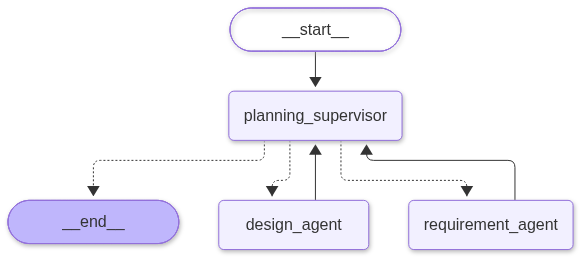

In [58]:
planning_builder = StateGraph(PlanningState)

planning_builder.add_node("planning_supervisor", planning_supervisor)
planning_builder.add_node("requirement_agent", requirement_agent)
planning_builder.add_node("design_agent", design_agent)

planning_builder.add_edge(START, "planning_supervisor")
planning_builder.add_edge("requirement_agent", "planning_supervisor")
planning_builder.add_edge("design_agent", "planning_supervisor")

planning_graph = planning_builder.compile()
planning_graph

In [59]:
# Development Team 코드 작성과 5개 항목 검토
def development_supervisor(s: DevelopmentState) -> Command[Literal["coding_agent", "review_agent", "__end__"]]:
    if s.get("reviewed", False):
        return Command(goto=END)
    if not s.get("code"):
        return Command(goto="coding_agent")
    if s.get("review") and not s.get("approved", False):
        return Command(goto="coding_agent")
    return Command(goto="review_agent")

# LLM이 생성한 코드에 불필요하게 붙이는 Markdown 코드 블록 표시를 제거하는 함수
"""
```python
def add(a, b):
    return a + b
```
이런식으로 LLM이 답변할 수 있는데
이때 불필요한 ```python과 ```를 제거하고 순수한 코드만 남기기 위해 strip_code_fences 함수 사용
"""
def strip_code_fences(text: str) -> str:
    value = text.strip()
    if value.startswith("```"):
        value = value.split("\n", 1)[-1] if "\n" in value else ""
        if value.rstrip().endswith("```"):
            value = value.rstrip()[:-3].rstrip()
    return value

# 코드 작성 에이전트
def coding_agent(s: DevelopmentState) -> dict:
    previous = s.get("code", "")
    feedback = s.get("review", "")
    prompt = (
        f"사용자 요청:\n{s['request']}\n\n요구사항:\n{s['requirements']}\n\n"
        f"설계:\n{s['design']}\n\n이전 코드:\n{previous}\n\n"
        f"이전 검토 의견:\n{feedback}\n"
    )
    generated = strip_code_fences(ask(
        "당신은 Python개발자입니다. Python 표준 라이브러리만 사용하고, "
        "설계의 모든 기능을 구현한 완전한 Python 소스 코드만 출력하세요. "
        "Markdown 코드펜스나 설명문을 출력하지 마세요."
        "사용자 요청에 명시된 필수 기능을 빠짐없이 구현하세요. "
        "입력 오류, 빈 데이터, 동점 처리 정책을 명확히 구현하세요."
        "input()을 호출하거나 모듈 import 시 자동 실행되는 코드를 만들지 마세요."
        "이전 코드와 검토 의견이 있다면 문제를 수정하세요.", prompt
    ))
    if not generated:
        raise ValueError("코드 생성 결과가 비어 있습니다.")
    return {
        "code": generated,
        "review": "",
        "approved": False,
        "reviewed": False,
        "revision_count": s.get("revision_count", 0) + (1 if previous else 0)
    }

# 코드 리뷰수행 에이전트
def review_agent(s: DevelopmentState) -> dict:
    result = get_review_llm().invoke([
        (
            "system",
            "당신은 엄격한 Python 코드 리뷰어입니다. 다음 다섯 항목을 각각 판단하세요: "
            "(1) 필수 기능 구현 (2) Python 문법 (3) 함수 분리 (4) 예외 처리 (5) 코드 가독성. "
            "모든 항목이 참일 때만 승입니다."
            "문제점과 수정 방법을 feedback에 구체적으로 작성하세요. "
            "코드를 실제 실행하지 않았으므로 실행 성공을 보증하지 마세요."
        ),
        (
            "human", f"사용자 요청:\n{s['request']}\n\n요구사항:\n{s['requirements']}\n\n"
            f"설계:\n{s['design']}\n\n코드:\n{s['code']}"
        )
    ])
    checks = {
        "필수 기능": result.features_ok, 
        "문법": result.syntax_ok,
        "함수 분리": result.functions_ok,
        "예외 처리": result.exceptions_ok,
        "가독성": result.readability_ok
    }
    checklist = "\n".join(f"- {name}: {'통과' if ok else '실패'}" for name, ok in checks.items())
    return {
        "approved": result.approved,
        "reviewed": True,
        "review": f"{checklist}\n\n검토 의견:\n{result.feedback}\n\n(실제 실행 검증은 수행하지 않음)"
    }

이제 또 그래프 그려보자고!

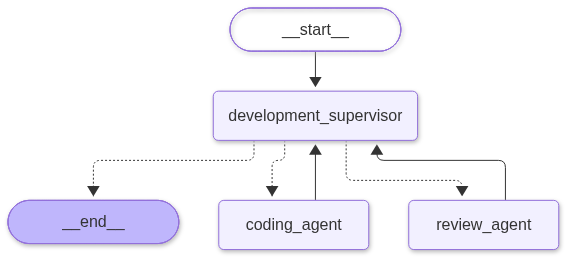

In [60]:
development_builder = StateGraph(DevelopmentState)

development_builder.add_node("development_supervisor", development_supervisor)
development_builder.add_node("coding_agent", coding_agent)
development_builder.add_node("review_agent", review_agent)

development_builder.add_edge(START, "development_supervisor")
development_builder.add_edge("coding_agent", "development_supervisor")
development_builder.add_edge("review_agent", "development_supervisor")

development_graph = development_builder.compile()
development_graph